# SDF (Signed Distance Field) 可視化

`binary_image_to_sdf` / `sdf_to_binary` / `sdf_to_smoothstep` の動作確認。

- ストローク内部 → 1.0（明るい）  
- 背景 → 0.0（暗い）  
- 輪郭（境界） → ≈ 0.5

`sdf_to_smoothstep`（Green/Valve 2007）: 閾値から±filter_width_px の範囲だけ連続補間し、
それ以外では完全に 0/1 を維持する。`sdf_to_binary`（ハード閾値）や sigmoid と比較する。

In [1]:
import sys
sys.path.insert(0, "../src")

from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

from real_fonts_vs_gen_fonts.sdf import binary_image_to_sdf, sdf_to_binary, sdf_to_smoothstep

IMAGE_DIR = Path("data/datasets/font2dataset_ascii_google/images")
IMAGE_SIZE = 64
MAX_DIST = 10.0

In [2]:
def load_binary(path: Path, threshold: float = 0.5) -> np.ndarray:
    """Load a font image as a binary (H,W) float32 array."""
    img = Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    arr = np.array(img, dtype=np.float32) / 255.0
    return (arr > threshold).astype(np.float32)

## 1. 元画像・二値化・SDF・ハード閾値・Smoothstep を並べて確認

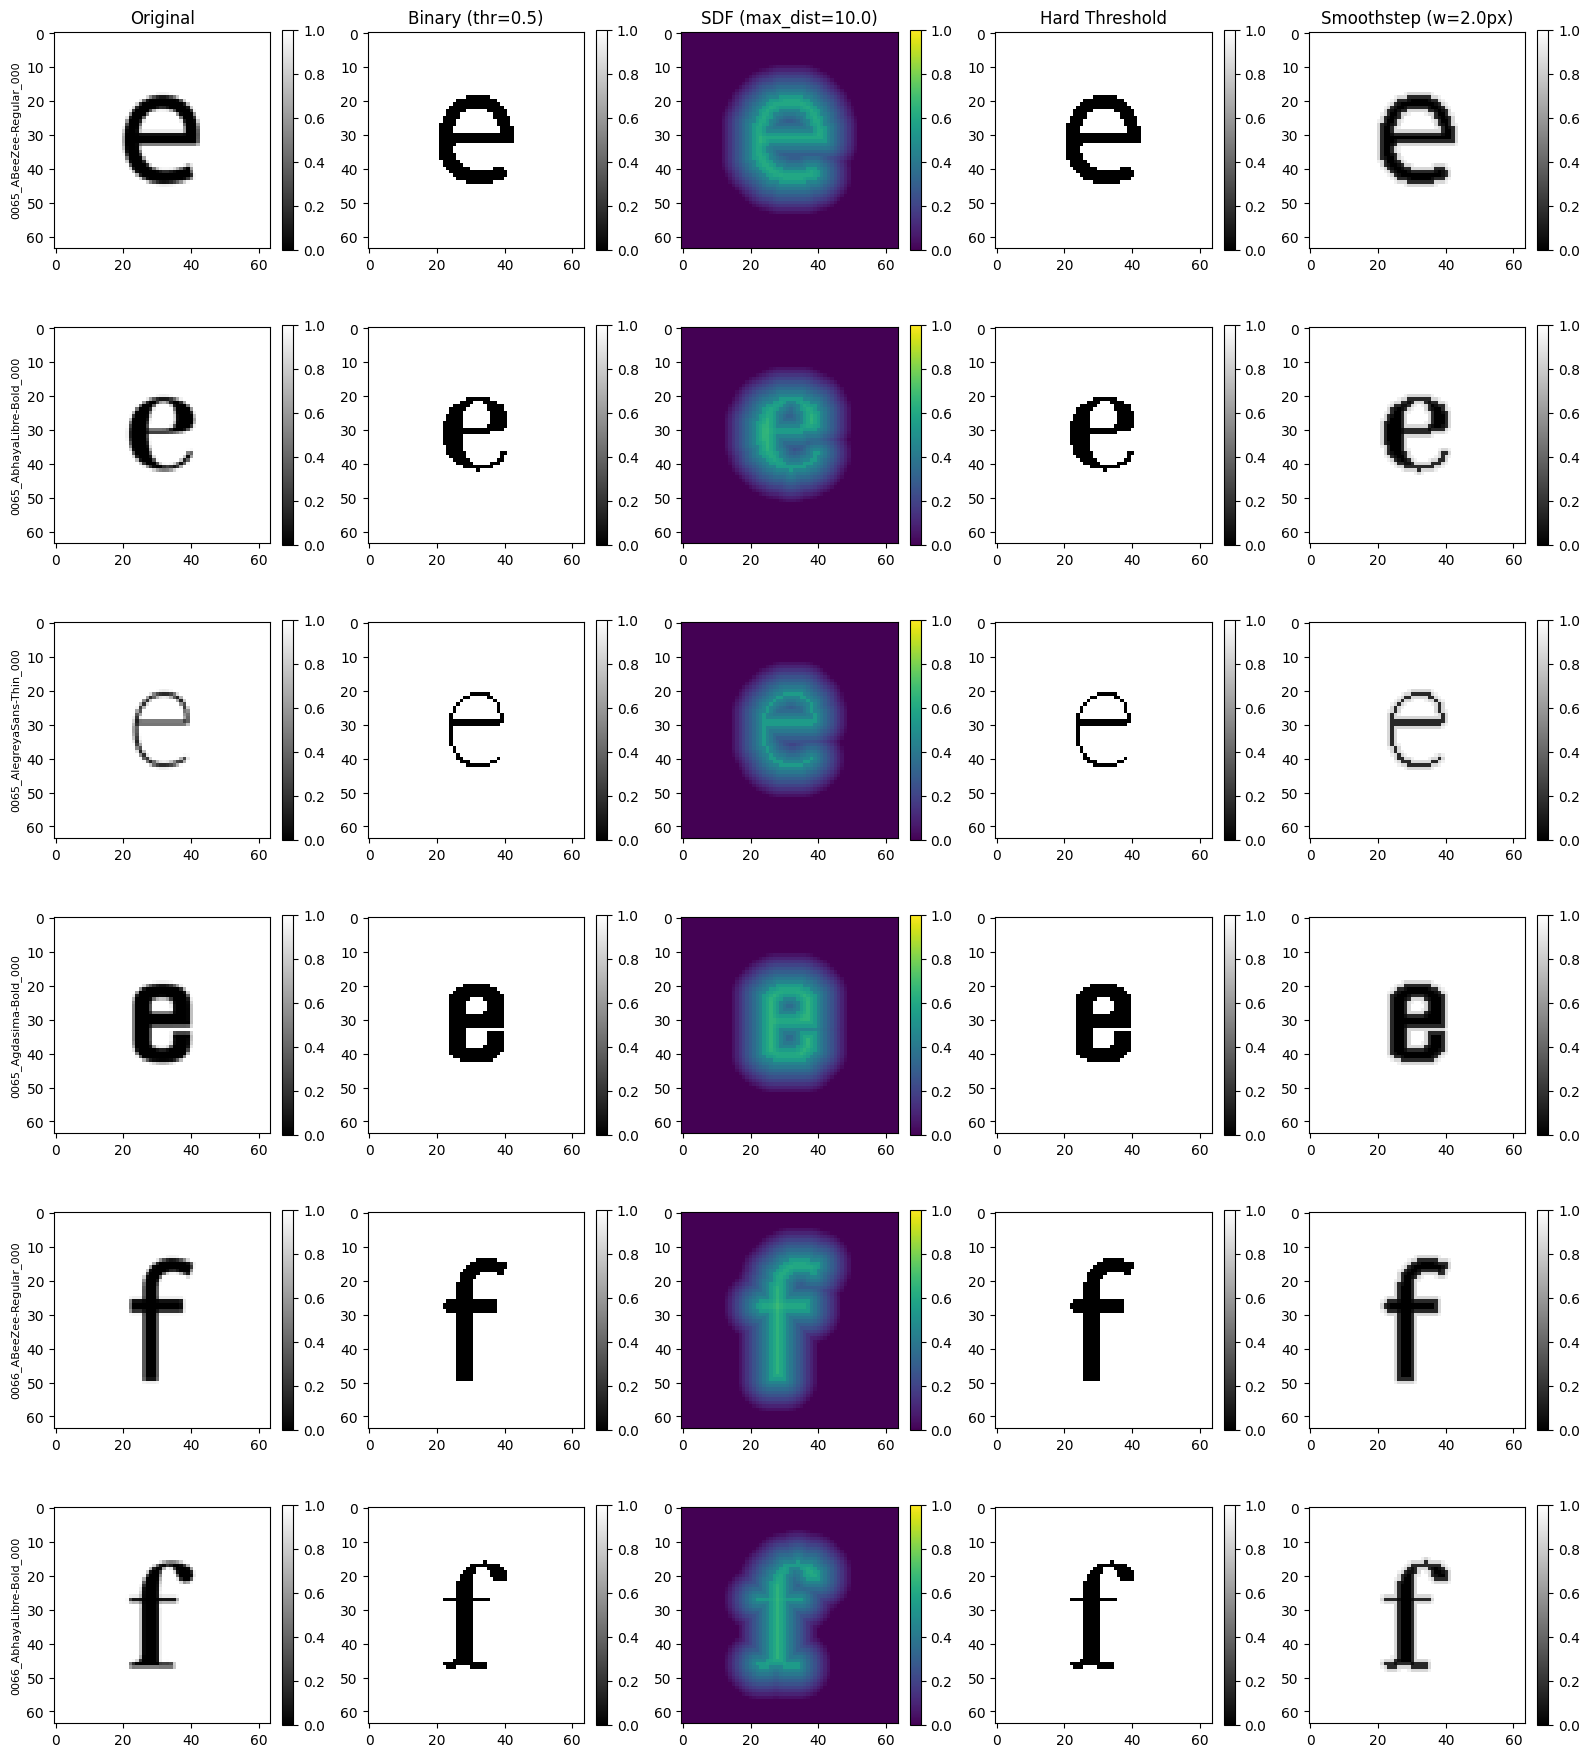

In [3]:
def load_binary(path: Path, threshold: float = 0.5) -> np.ndarray:
    """Load a font image as a binary (H,W) float32 array."""
    img = Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
    arr = np.array(img, dtype=np.float32) / 255.0
    return (arr > threshold).astype(np.float32)


sample_paths = [
    IMAGE_DIR / "0065_ABeeZee-Regular_000.png",
    IMAGE_DIR / "0065_AbhayaLibre-Bold_000.png",
    IMAGE_DIR / "0065_AlegreyaSans-Thin_000.png",
    IMAGE_DIR / "0065_Agdasima-Bold_000.png",
    IMAGE_DIR / "0066_ABeeZee-Regular_000.png",
    IMAGE_DIR / "0066_AbhayaLibre-Bold_000.png",
]
sample_paths = [p for p in sample_paths if p.exists()]

FILTER_WIDTH_PX = 2.0  # smoothstep のフィルタ幅 (px)

n = len(sample_paths)
cols = ["Original", "Binary (thr=0.5)", f"SDF (max_dist={MAX_DIST})", "Hard Threshold", f"Smoothstep (w={FILTER_WIDTH_PX}px)"]
fig, axes = plt.subplots(n, 5, figsize=(16, 3 * n))

for ax_row, path in zip(axes, sample_paths):
    raw = np.array(Image.open(path).convert("L").resize((IMAGE_SIZE, IMAGE_SIZE)), dtype=np.float32) / 255.0
    binary = load_binary(path)
    sdf = binary_image_to_sdf(binary, max_dist=MAX_DIST)
    hard = sdf_to_binary(sdf)
    sdf_t = torch.from_numpy(sdf if sdf.ndim == 2 else sdf[0])
    smooth = sdf_to_smoothstep(sdf_t, filter_width_px=FILTER_WIDTH_PX, max_dist=MAX_DIST).numpy()

    images = [raw, binary, sdf if sdf.ndim == 2 else sdf[0], hard if hard.ndim == 2 else hard[0], smooth]
    cmaps = ["gray", "gray", "viridis", "gray", "gray"]
    for ax, img, cmap in zip(ax_row, images, cmaps):
        im = ax.imshow(img, cmap=cmap, vmin=0, vmax=1)
        plt.colorbar(im, ax=ax, fraction=0.046)

    ax_row[0].set_ylabel(path.stem[:30], fontsize=8)

for ax, col in zip(axes[0], cols):
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 2. max_dist を変えたときの SDF の違い

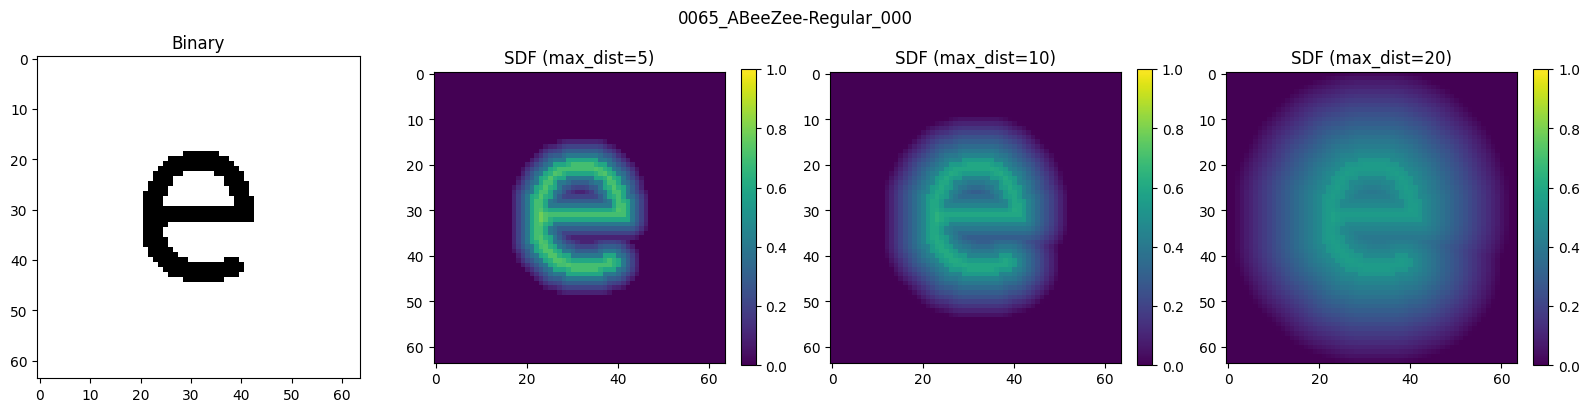

In [4]:
target_path = next((p for p in sample_paths if p.exists()), None)
binary = load_binary(target_path)

max_dists = [5, 10, 20]
fig, axes = plt.subplots(1, len(max_dists) + 1, figsize=(4 * (len(max_dists) + 1), 4))

axes[0].imshow(binary, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Binary")

for ax, md in zip(axes[1:], max_dists):
    sdf = binary_image_to_sdf(binary, max_dist=md)
    im = ax.imshow(sdf, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"SDF (max_dist={md})")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle(target_path.stem)
plt.tight_layout()
plt.show()

## 3. 細字・太字フォントの SDF 値分布（ヒストグラム）

- 細字: SDF が 0 or 1 に集中（ストローク面積が小さい）
- 太字: 0.5 より大きい領域（ストローク内部）が広い

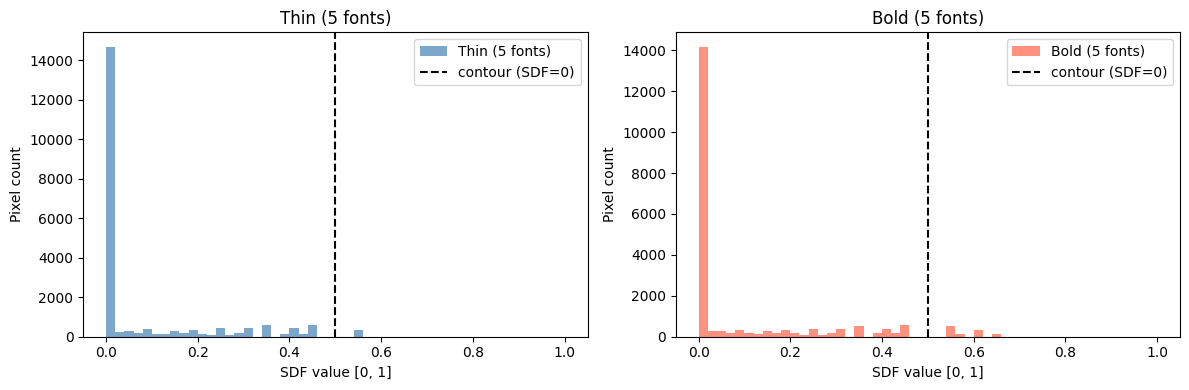

Thin  - stroke fraction (SDF>0.5): 0.017
Bold  - stroke fraction (SDF>0.5): 0.054


In [5]:
thin_paths = list(IMAGE_DIR.glob("0065_*Thin*_000.png"))[:5]
bold_paths = list(IMAGE_DIR.glob("0065_*Bold*_000.png"))[:5]

def sdf_values(paths, max_dist=10.0):
    vals = []
    for p in paths:
        b = load_binary(p)
        s = binary_image_to_sdf(b, max_dist=max_dist)
        vals.append(s.ravel())
    return np.concatenate(vals) if vals else np.array([])

thin_vals = sdf_values(thin_paths)
bold_vals = sdf_values(bold_paths)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, vals, label, color in zip(
    axes,
    [thin_vals, bold_vals],
    [f"Thin ({len(thin_paths)} fonts)", f"Bold ({len(bold_paths)} fonts)"],
    ["steelblue", "tomato"],
):
    ax.hist(vals, bins=50, range=(0, 1), color=color, alpha=0.7, label=label)
    ax.axvline(0.5, color="black", linestyle="--", label="contour (SDF=0)")
    ax.set_xlabel("SDF value [0, 1]")
    ax.set_ylabel("Pixel count")
    ax.set_title(label)
    ax.legend()

plt.tight_layout()
plt.show()

if len(thin_vals) and len(bold_vals):
    print(f"Thin  - stroke fraction (SDF>0.5): {(thin_vals > 0.5).mean():.3f}")
    print(f"Bold  - stroke fraction (SDF>0.5): {(bold_vals > 0.5).mean():.3f}")

## 4. 再二値化の精度確認（Binary == Recovered Binary）

In [6]:
all_paths = list(IMAGE_DIR.glob("0065_*_000.png"))[:50]
pixel_errors = []

for p in all_paths:
    b = load_binary(p)
    sdf = binary_image_to_sdf(b, max_dist=10.0)
    recovered = sdf_to_binary(sdf)
    err = np.abs(b - recovered).mean()
    pixel_errors.append(err)

pixel_errors = np.array(pixel_errors)
print(f"Pixel-level reconstruction error (mean over {len(all_paths)} images):")
print(f"  mean={pixel_errors.mean():.6f}, max={pixel_errors.max():.6f}")
print("→ 完全一致なら 0.0 になるはず（離散グリッドの境界で 1px 程度のずれが出ることがある）")

Pixel-level reconstruction error (mean over 50 images):
  mean=0.000000, max=0.000000
→ 完全一致なら 0.0 になるはず（離散グリッドの境界で 1px 程度のずれが出ることがある）


## 5. デコード手法の比較（Hard / Sigmoid / Smoothstep）

エッジをまたぐ 1 行の水平断面で各手法の遷移プロファイルを比較する。  
- **Hard**: 閾値でステップ関数。エッジ外は完全に 0/1  
- **Sigmoid(sharpness=30)**: 全ピクセルに柔らかい裾野が残る  
- **Smoothstep(w=1px)**: 遷移帯 ±w だけ補間し、遠方は完全に 0/1（Green/Valve 2007）

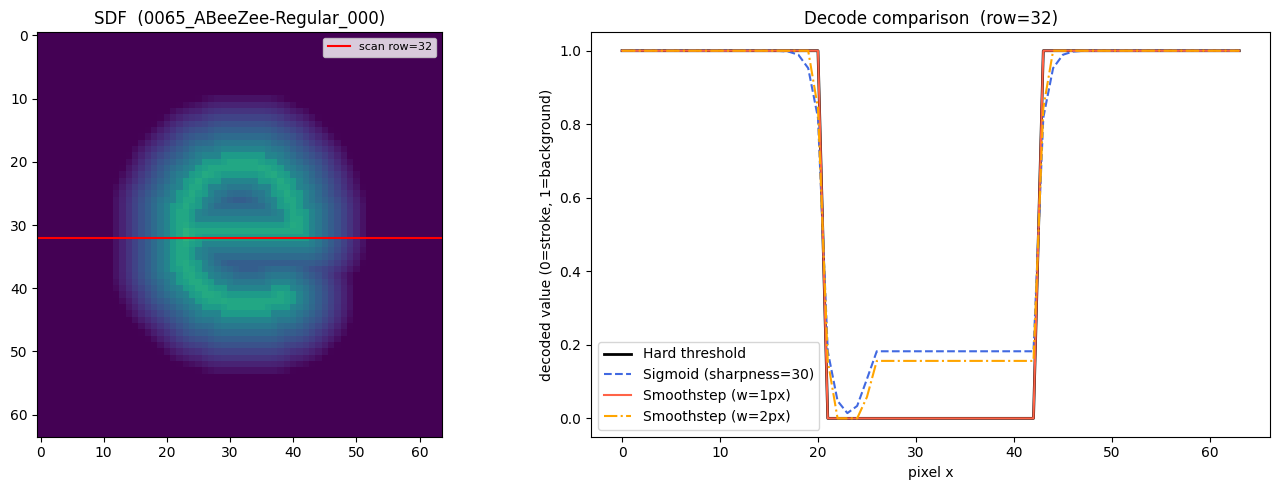

In [7]:
target_path = next((p for p in sample_paths if p.exists()), None)
binary = load_binary(target_path)
sdf = binary_image_to_sdf(binary, max_dist=MAX_DIST)
sdf_t = torch.from_numpy(sdf if sdf.ndim == 2 else sdf[0])

hard = sdf_to_binary(sdf_t).numpy()
sigmoid_30 = sdf_to_binary(sdf_t, sharpness=30.0).numpy()
smooth_1px = sdf_to_smoothstep(sdf_t, filter_width_px=1.0, max_dist=MAX_DIST).numpy()
smooth_2px = sdf_to_smoothstep(sdf_t, filter_width_px=2.0, max_dist=MAX_DIST).numpy()

# エッジを含む行を自動検出（hard output の 0/1 が混在する最初の行）
sdf_2d = sdf if sdf.ndim == 2 else sdf[0]
edge_rows = np.where((hard > 0).any(axis=1) & (hard < 1).any(axis=1))[0]
row_idx = int(edge_rows[len(edge_rows) // 2]) if len(edge_rows) else IMAGE_SIZE // 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左: 元画像にスキャンライン表示
ax = axes[0]
ax.imshow(sdf_2d, cmap="viridis", vmin=0, vmax=1)
ax.axhline(row_idx, color="red", linewidth=1.5, label=f"scan row={row_idx}")
ax.set_title(f"SDF  ({target_path.stem[:30]})")
ax.legend(fontsize=8)

# 右: 各手法の1Dプロファイル
ax = axes[1]
x = np.arange(IMAGE_SIZE)
ax.plot(x, hard[row_idx],      color="black",    linewidth=2,   label="Hard threshold")
ax.plot(x, sigmoid_30[row_idx], color="royalblue", linewidth=1.5, linestyle="--", label="Sigmoid (sharpness=30)")
ax.plot(x, smooth_1px[row_idx], color="tomato",   linewidth=1.5, label="Smoothstep (w=1px)")
ax.plot(x, smooth_2px[row_idx], color="orange",   linewidth=1.5, linestyle="-.", label="Smoothstep (w=2px)")
ax.set_xlabel("pixel x")
ax.set_ylabel("decoded value (0=stroke, 1=background)")
ax.set_title(f"Decode comparison  (row={row_idx})")
ax.legend()
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

## 6. filter_width_px のスイープ（Smoothstep エッジ幅の影響）

`filter_width_px` を変えたときの画像レベルの差異を確認する。  
64px 画像では 1px が標準。大きくするとアンチエイリアシングが強くなりぼけが増す。

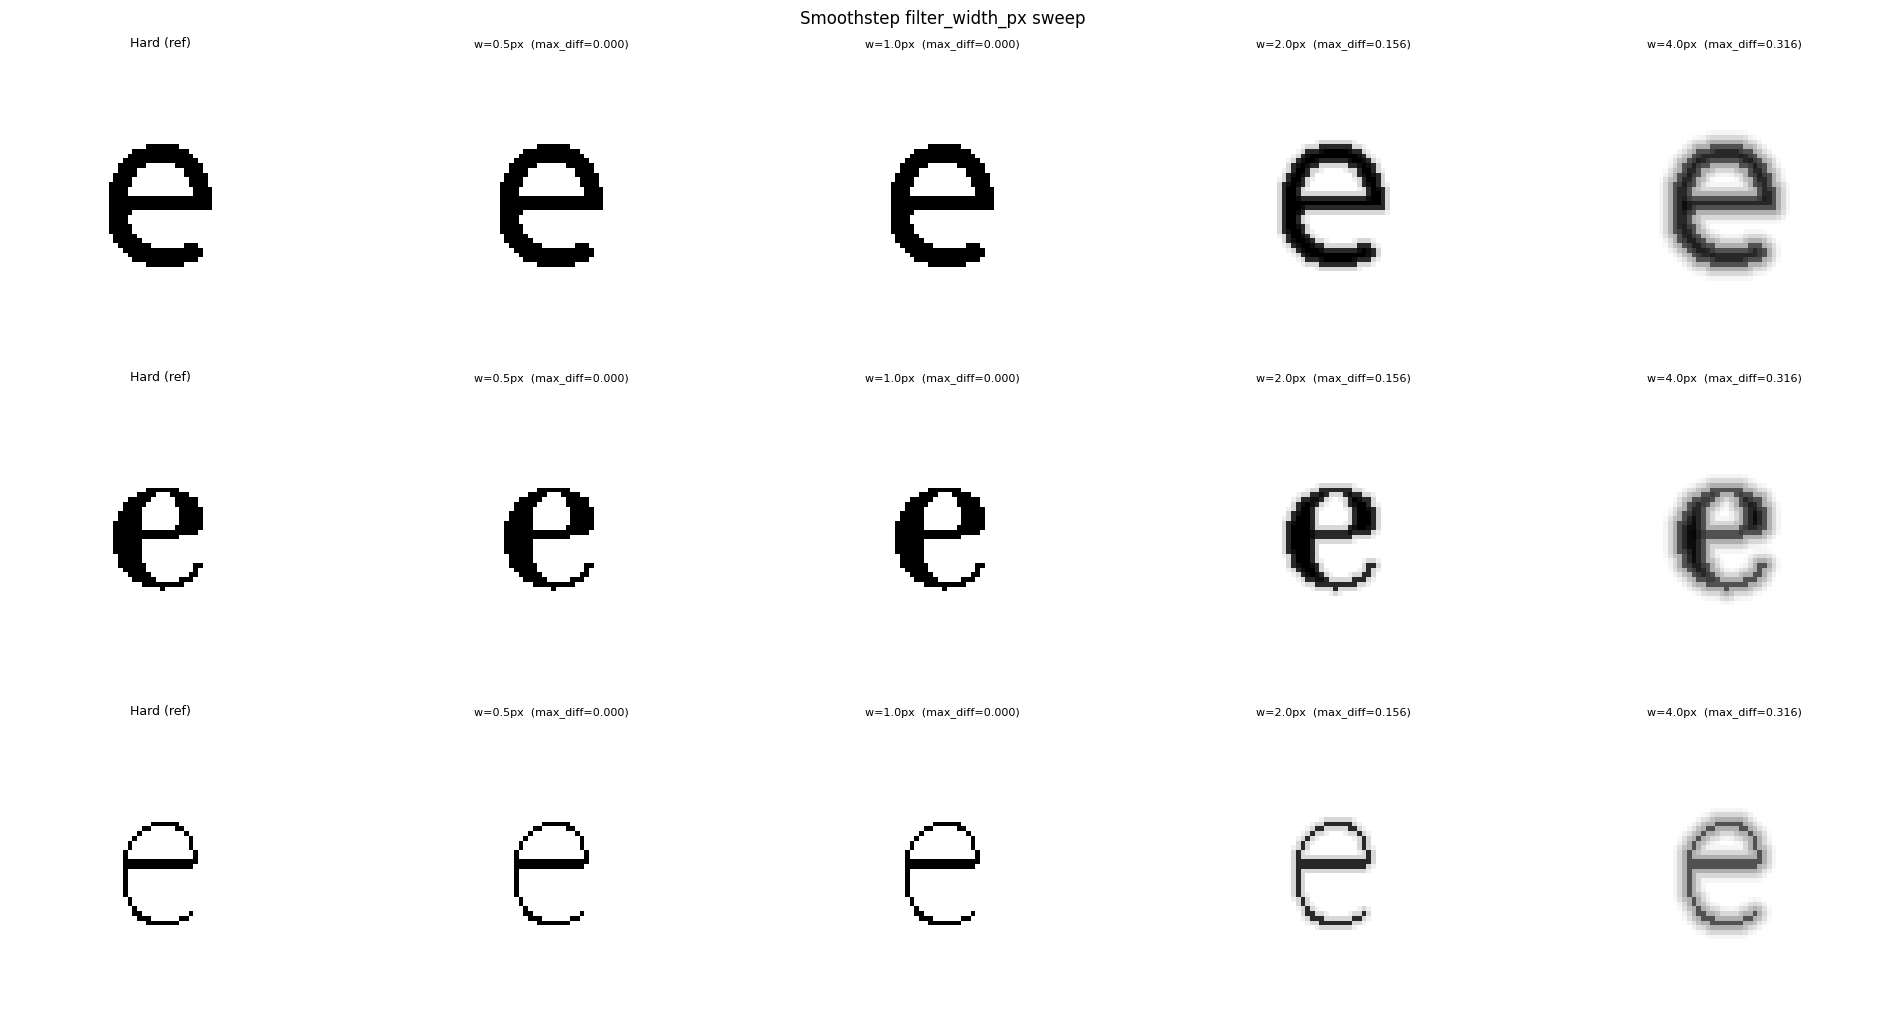

In [8]:
filter_widths = [0.5, 1.0, 2.0, 4.0]

n_paths = min(3, len(sample_paths))
fig, axes = plt.subplots(n_paths, len(filter_widths) + 1, figsize=(4 * (len(filter_widths) + 1), 3.5 * n_paths))

for row_ax, path in zip(axes, sample_paths[:n_paths]):
    binary = load_binary(path)
    sdf = binary_image_to_sdf(binary, max_dist=MAX_DIST)
    sdf_2d = sdf if sdf.ndim == 2 else sdf[0]
    sdf_t = torch.from_numpy(sdf_2d)

    # 1列目: Hard threshold（基準）
    hard = sdf_to_binary(sdf_t).numpy()
    row_ax[0].imshow(hard, cmap="gray", vmin=0, vmax=1)
    row_ax[0].set_title("Hard (ref)", fontsize=9)
    row_ax[0].set_ylabel(path.stem[:25], fontsize=7)
    row_ax[0].axis("off")

    for ax, fw in zip(row_ax[1:], filter_widths):
        sm = sdf_to_smoothstep(sdf_t, filter_width_px=fw, max_dist=MAX_DIST).numpy()
        # 差分の最大値をタイトルに表示
        max_diff = float(np.abs(sm - hard).max())
        ax.imshow(sm, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"w={fw}px  (max_diff={max_diff:.3f})", fontsize=8)
        ax.axis("off")

plt.suptitle("Smoothstep filter_width_px sweep", fontsize=12)
plt.tight_layout()
plt.show()

## 7. ストローク幅の実測 → max_dist の上限を決める

SDF の遷移帯は輪郭から ±max_dist px。**max_dist > (ストロークの半幅) になるとストローク内部が
1.0 に飽和せず、灰色の尾根のまま**になる（細ストロークを solid に残せない）。

そこで「max_dist ≲ 最も細いストロークの半幅」が上限の目安。ここでは
`distance_transform_edt` の**内部距離のリッジ（中心線）**を半幅の推定値として測る:

- 各ストローク画素の内部距離 `dist_in` を計算
- 局所最大（`maximum_filter` と一致する画素 = 中心線）を抽出 → その値 ≈ 半幅
- 多数フォントで集計し、半幅の分布から max_dist の許容範囲を読む

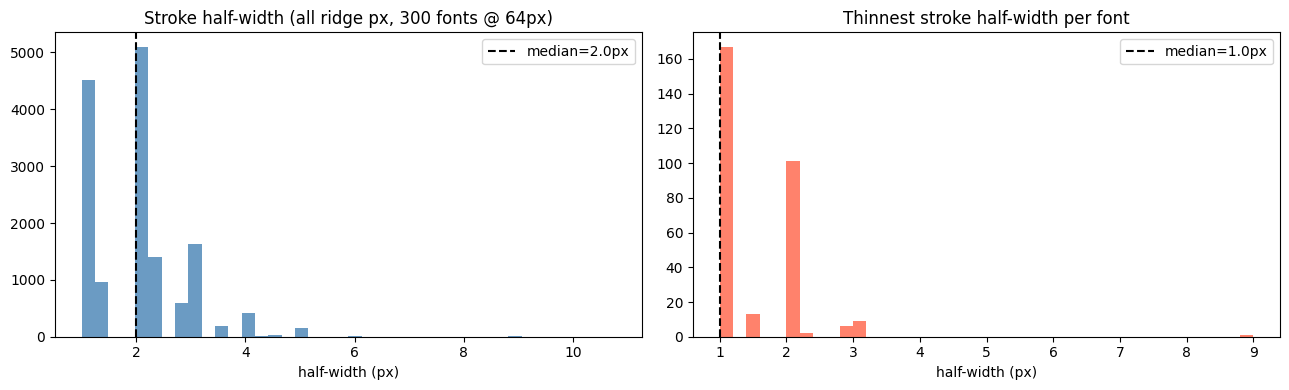

@ 64px  ストローク半幅:
  全リッジ:        median=2.00px, p10=1.00, p90=3.00
  各フォント最細:  median=1.00px, p10=1.00px

→ 内部飽和を保つ max_dist の上限目安 ≈ 全リッジ median 2.0px (= ストローク半幅)。細字まで残すなら 1〜2px。
→ 現状 config (MAX_DIST=10.0) は上限の約 5 倍。このデータは線が細く、どの設定でも glyph 全体がランプ＝内部飽和ほぼ 0。
→ つまり max_dist の実効的な役割は『内部の solid 化』ではなく『輪郭の傾き＝0.5 レベルセットの位置精度』。大きいほどエッジがボケやすい (傾き 1/(2·max_dist))。


In [9]:
from scipy.ndimage import distance_transform_edt, maximum_filter


def stroke_half_widths(binary: np.ndarray) -> np.ndarray:
    """Estimate stroke half-widths (px) from the medial axis ridge of dist_in.

    binary: (H,W) with stroke=0, background=1.
    Returns the dist_in values along the ridge (≈ half-width at each centerline pixel).
    """
    stroke_mask = binary < 0.5
    if not stroke_mask.any():
        return np.array([])
    dist_in = distance_transform_edt(stroke_mask).astype(np.float32)
    # ridge = local maxima of dist_in (medial axis), excluding the contour band (dist<1)
    ridge = (dist_in == maximum_filter(dist_in, size=3)) & (dist_in >= 1.0)
    return dist_in[ridge]


# 多数フォント (A=0065) で半幅を集計
width_paths = sorted(IMAGE_DIR.glob("0065_*_000.png"))[:300]
all_hw = []
per_font_min_hw = []  # 各フォントの最も細いストローク半幅
for p in width_paths:
    hw = stroke_half_widths(load_binary(p))
    if len(hw):
        all_hw.append(hw)
        per_font_min_hw.append(hw.min())
all_hw = np.concatenate(all_hw) if all_hw else np.array([])
per_font_min_hw = np.array(per_font_min_hw)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(all_hw, bins=40, color="steelblue", alpha=0.8)
axes[0].axvline(np.median(all_hw), color="black", ls="--", label=f"median={np.median(all_hw):.1f}px")
axes[0].set_title(f"Stroke half-width (all ridge px, {len(width_paths)} fonts @ {IMAGE_SIZE}px)")
axes[0].set_xlabel("half-width (px)"); axes[0].legend()

axes[1].hist(per_font_min_hw, bins=40, color="tomato", alpha=0.8)
axes[1].axvline(np.median(per_font_min_hw), color="black", ls="--", label=f"median={np.median(per_font_min_hw):.1f}px")
axes[1].set_title("Thinnest stroke half-width per font")
axes[1].set_xlabel("half-width (px)"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"@ {IMAGE_SIZE}px  ストローク半幅:")
print(f"  全リッジ:        median={np.median(all_hw):.2f}px, "
      f"p10={np.percentile(all_hw, 10):.2f}, p90={np.percentile(all_hw, 90):.2f}")
print(f"  各フォント最細:  median={np.median(per_font_min_hw):.2f}px, "
      f"p10={np.percentile(per_font_min_hw, 10):.2f}px")

sat_limit = float(np.median(all_hw))  # 内部飽和を保てる max_dist の上限目安
print(f"\n→ 内部飽和を保つ max_dist の上限目安 ≈ 全リッジ median {sat_limit:.1f}px "
      f"(= ストローク半幅)。細字まで残すなら 1〜2px。")
print(f"→ 現状 config (MAX_DIST={MAX_DIST}) は上限の約 {MAX_DIST / sat_limit:.0f} 倍。"
      f"このデータは線が細く、どの設定でも glyph 全体がランプ＝内部飽和ほぼ 0。")
print("→ つまり max_dist の実効的な役割は『内部の solid 化』ではなく『輪郭の傾き＝"
      "0.5 レベルセットの位置精度』。大きいほどエッジがボケやすい (傾き 1/(2·max_dist))。")

## 8. 解像度スケーリング: 線形(×2) vs 二乗(×4)

64px → 128px と解像度を 2 倍にしたとき max_dist をどうスケールすべきか。

- max_dist は**距離（長さ）**。長さは解像度に**線形**でスケールするので、相対パリティを保つなら
  **×2（10 → 20）が次元的に正しい**。
- 「面積が 4 倍だから ×4」は次元エラー（max_dist は面積ではない）。

**検証方法（parity MSE）**: 128px で作った SDF を 64px に縮小し、64px/max_dist=10 の SDF と
比較する。正しいスケールなら正規化された距離場が一致し MSE≈0 になる。
（前セクションのとおりこのデータセットはストロークが細く interior saturation はどの設定でも
ほぼ 0 なので、飽和率では差が出ない。スケール不変性そのものを測る parity MSE で判定する。）

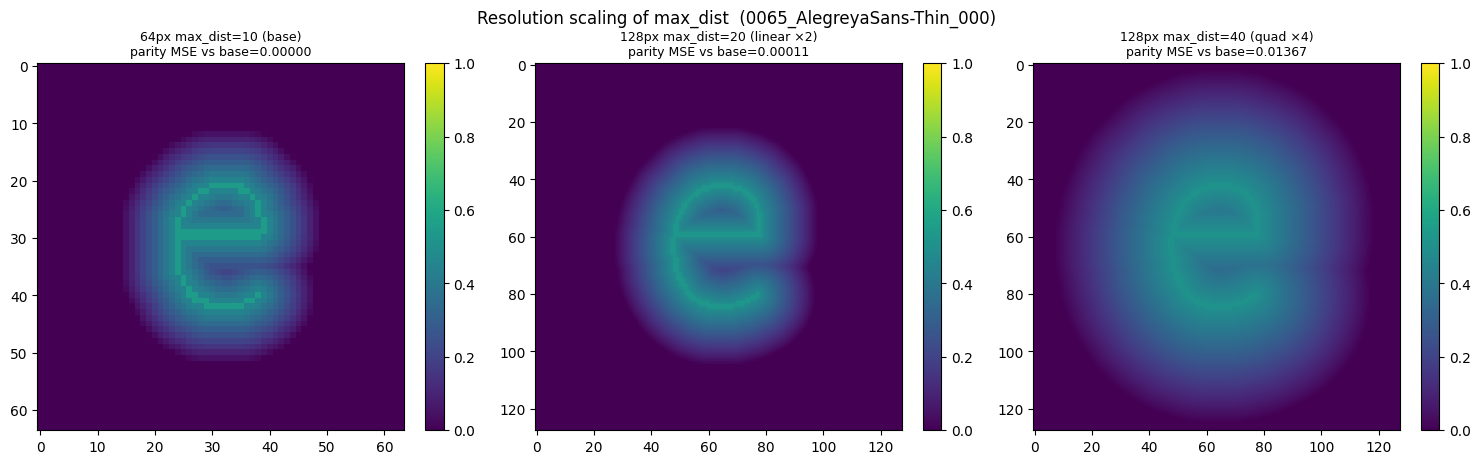

parity MSE（128px SDF を 64px に縮小し base と比較; 小さいほどスケール整合）:
  128px max_dist=20 (linear ×2)    MSE=0.00011
  128px max_dist=40 (quad ×4)      MSE=0.01367
  128px max_dist=10 (no scaling)   MSE=0.00521

→ 線形(×2) が最小 MSE＝64px 基準と整合。二乗(×4) も無スケールも外れる。


In [10]:
def load_binary_at(path: Path, size: int, threshold: float = 0.5) -> np.ndarray:
    """Load a font image binarized at a given resolution."""
    img = Image.open(path).convert("L").resize((size, size))
    arr = np.array(img, dtype=np.float32) / 255.0
    return (arr > threshold).astype(np.float32)


def sdf_2d_at(path: Path, size: int, max_dist: float) -> np.ndarray:
    sdf = binary_image_to_sdf(load_binary_at(path, size), max_dist=max_dist)
    return sdf if sdf.ndim == 2 else sdf[0]


def downscale(a: np.ndarray, size: int) -> np.ndarray:
    """Bilinear downscale an SDF map to `size` for parity comparison."""
    img = Image.fromarray((a * 255).astype(np.uint8)).resize((size, size), Image.BILINEAR)
    return np.array(img, dtype=np.float32) / 255.0


src = next((p for p in (
    IMAGE_DIR / "0065_AlegreyaSans-Thin_000.png",
    IMAGE_DIR / "0065_ABeeZee-Regular_000.png",
) if p.exists()), sorted(IMAGE_DIR.glob("0065_*_000.png"))[0])

base64 = sdf_2d_at(src, 64, 10.0)  # 64px reference
configs = [
    ("64px max_dist=10 (base)", 64, 10.0),
    ("128px max_dist=20 (linear ×2)", 128, 20.0),
    ("128px max_dist=40 (quad ×4)", 128, 40.0),
]

fig, axes = plt.subplots(1, len(configs), figsize=(15, 4.5))
for ax, (label, size, md) in zip(axes, configs):
    field = sdf_2d_at(src, size, md)
    mse = np.mean((downscale(field, 64) - base64) ** 2) if size != 64 else 0.0
    im = ax.imshow(field, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"{label}\nparity MSE vs base={mse:.5f}", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle(f"Resolution scaling of max_dist  ({src.stem})", fontsize=12)
plt.tight_layout(); plt.show()

print("parity MSE（128px SDF を 64px に縮小し base と比較; 小さいほどスケール整合）:")
for label, size, md in configs:
    if size == 64:
        continue
    mse = np.mean((downscale(sdf_2d_at(src, size, md), 64) - base64) ** 2)
    print(f"  {label:<32} MSE={mse:.5f}")
# 参考: スケールしない場合（128px で md=10 のまま）
mse_noscale = np.mean((downscale(sdf_2d_at(src, 128, 10.0), 64) - base64) ** 2)
print(f"  {'128px max_dist=10 (no scaling)':<32} MSE={mse_noscale:.5f}")
print("\n→ 線形(×2) が最小 MSE＝64px 基準と整合。二乗(×4) も無スケールも外れる。")